# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from statsmodels.base.model import GenericLikelihoodModel

# 1)
- Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64


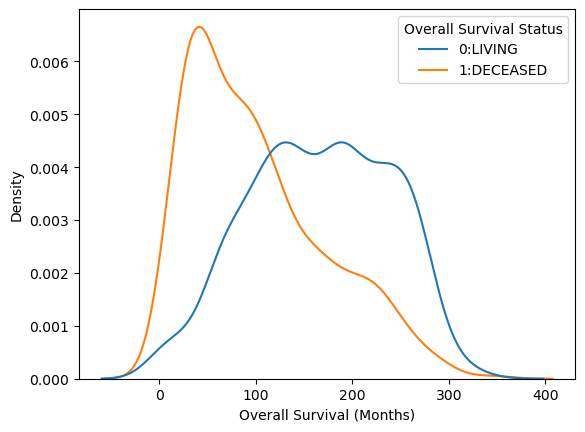

In [14]:
df = pd.read_csv("./data/metabric.csv")
print(df["Overall Survival Status"].value_counts())
sns.kdeplot(data=df, x="Overall Survival (Months)", hue="Overall Survival Status", common_norm=False)
plt.show()

num_vars = ["Age at Diagnosis", "Lymph nodes examined positive", "Mutation Count", "Tumor Size"]
cat_vars = ["Chemotherapy", "Hormone Therapy", "Radio Therapy", "Tumor Stage"]

df = df[df["Tumor Stage"] != 0]
df["event"] = df["Overall Survival Status"].astype(str).str.contains("DECEASED|^1", regex=True).astype(int)

# 2) 
- Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.

In [15]:
X = pd.get_dummies(df[num_vars + cat_vars], columns=cat_vars, drop_first=True, dtype=float)
X = sm.add_constant(X)
df["log_months"] = np.log(df["Overall Survival (Months)"])

train, test = train_test_split(df, test_size=0.2, random_state=0)
X_train, X_test = X.loc[train.index], X.loc[test.index]
y_train = train["log_months"]

ols_all = sm.OLS(y_train, X_train).fit()
dead = train["event"] == 1
ols_dead = sm.OLS(y_train[dead], X_train[dead]).fit()

pred_all = X_test @ ols_all.params
pred_dead = X_test @ ols_dead.params

- Imputation: for a living patient we only know survival time is at least the time of the survey. Using the follow up as the target imputes the lower bound as if it were the true survival time, so outcomes are too small, especially for groups with lots of censoring.
- Missing data: dropping the living treats those outcomes as missing, but who is missing depends on the outcome itself since people who live longer are the ones being dropped. So it is missing not at random and the remaining sample is skewed toward short survival

# 3) 
- Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).

With z_i = (y_i − x_i * beta)/sigma and d_i = 1 for an observed death: LL(beta, sigma) = SUM(d_i * [ −log(sigma) + log(PHI(z_i))] + (1 − d_i) · log(1 − PHI(z_i)) )

# 4) 
- We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.

In [16]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                          CensoredNormalMLE Results                           
Dep. Variable:             log_months   Log-Likelihood:                -1160.8
Model:              CensoredNormalMLE   AIC:                             2346.
Method:            Maximum Likelihood   BIC:                             2405.
Date:                Tue, 17 Nov 2026                                         
Time:                        15:41:48                                         
No. Observations:                1072                                         
Df Residuals:                    1060                                         
Df Model:                          10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             6.6822      0.215     31.118      0.000    

# 5)
- Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [17]:
k = X_train.shape[1]
display(pd.DataFrame({"Imputation OLS": ols_all.params.values,
                    "Dropped-alive OLS": ols_dead.params.values,
                    "Censored MLE": np.asarray(mle.params)[:k]},
                   index=X_train.columns).round(4))

cmp = test.assign(p_all=pred_all, p_dead=pred_dead, p_mle=X_test @ np.asarray(mle.params)[:k])

d = cmp[cmp["event"] == 1]
print({c: np.sqrt(((d[c] - d["log_months"])**2).mean()).round(3) for c in ["p_all", "p_dead", "p_mle"]})

# Bias vs. censored MLE, by group
bias = cmp[["p_all", "p_dead"]].sub(cmp["p_mle"], axis=0)
groups = [cmp[g] for g in ["Tumor Stage", "Chemotherapy", "Hormone Therapy", "Radio Therapy"]]
groups.append(pd.qcut(cmp["Age at Diagnosis"], 4))
for g in groups:
    print(bias.groupby(g, observed=True).mean().round(3))

,Imputation OLS,Dropped-alive OLS,Censored MLE
const,5.3532,4.6571,6.6822
Age at Diagnosis,-0.0094,-0.0022,-0.0222
Lymph nodes examined positive,-0.0336,-0.0275,-0.0502
Mutation Count,0.0132,0.0132,-0.0046
Tumor Size,-0.0025,-0.0004,-0.0062
Chemotherapy_YES,-0.2111,-0.4037,-0.2433
Hormone Therapy_YES,0.0819,0.2238,0.2882
Radio Therapy_YES,0.0666,0.0301,0.1495
Tumor Stage_2.0,-0.2648,-0.3278,-0.3735
Tumor Stage_3.0,-0.3790,-0.5434,-0.5606


{'p_all': np.float64(0.987), 'p_dead': np.float64(0.957), 'p_mle': np.float64(1.144)}
             p_all  p_dead
Tumor Stage               
1.0         -0.556  -0.780
2.0         -0.390  -0.619
3.0         -0.177  -0.520
4.0         -0.203  -0.355
              p_all  p_dead
Chemotherapy               
NO           -0.430  -0.597
YES          -0.423  -0.901
                 p_all  p_dead
Hormone Therapy               
NO              -0.409  -0.770
YES             -0.443  -0.589
               p_all  p_dead
Radio Therapy               
NO            -0.365  -0.549
YES           -0.460  -0.725
                  p_all  p_dead
Age at Diagnosis               
(28.619, 50.26]  -0.595  -1.041
(50.26, 60.3]    -0.496  -0.780
(60.3, 68.47]    -0.392  -0.554
(68.47, 86.75]   -0.224  -0.279


- Coefficients: Both OLS models have a lower intercept than the censored MLE. They also understate how strongly Age at Diagnosis and Tumor Size reduce survival
- Predictions and censoring: The OLS models look better on RMSE only because the test deaths are the short, uncensored survival times. For living patients, the censored MLE correctly predicts survival beyond the observed follow up.
- Biased groups: Both OLS models underpredict survival in every group. The bias is largest for younger patients and for Stage 1, so those are the groups with the most censoring